## 1. Importar librerias

Carga OpenCV, NumPy, Pillow y Matplotlib.

In [1]:
import cv2
import numpy as np
from PIL import Image, ImageOps
import matplotlib.pyplot as plt
print(cv2.__version__)

5.0.0


## 2. Seleccionar y cargar el documento

Busca JPG, PNG y PDF en `samples`, muestra un selector y convierte el PDF a imagen.

In [2]:
from pathlib import Path
import ipywidgets as widgets
import fitz

CARPETA = Path("../samples")
ARCHIVOS = sorted([
    p for p in CARPETA.iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".pdf"}
])

print("Archivos disponibles:", *[p.name for p in ARCHIVOS], sep="\n")

selector = widgets.Dropdown(
    options=[(p.name, p) for p in ARCHIVOS],
    description="Archivo:",
)
if not ARCHIVOS:
    print("No se encontraron JPG, JPEG, PNG ni PDF en ../samples")
mostrar = widgets.Button(description="Cargar", disabled=not ARCHIVOS)
resultado = widgets.Output()

def cargar(_=None):
    global img
    RUTA = selector.value

    if RUTA.suffix.lower() == ".pdf":
        pdf = fitz.open(RUTA)
        pagina = pdf[0]
        pixmap = pagina.get_pixmap(matrix=fitz.Matrix(2, 2), alpha=False)
        img = np.frombuffer(pixmap.samples, dtype=np.uint8)
        img = img.reshape(pixmap.height, pixmap.width, 3)
        pdf.close()
        titulo = f"{RUTA.name} - pagina 1"
    else:
        img = np.array(ImageOps.exif_transpose(Image.open(RUTA)).convert("RGB"))
        titulo = RUTA.name

    with resultado:
        resultado.clear_output()
        print(img.shape, img.dtype)
        plt.figure(figsize=(6, 8))
        plt.imshow(img)
        plt.title(titulo)
        plt.axis("off")
        plt.show()

mostrar.on_click(cargar)
display(widgets.HBox([selector, mostrar]), resultado)
if ARCHIVOS:
    cargar()

Archivos disponibles:
CV Pablo_Speranza_Mar 25.pdf
Screenshot_20190930-094706_Facebook.jpg
Screenshot_20191024-140707_WhatsApp.jpg


Output()

## 3. Detectar bordes

Reduce la imagen, la pasa a escala de grises y calcula sus bordes.

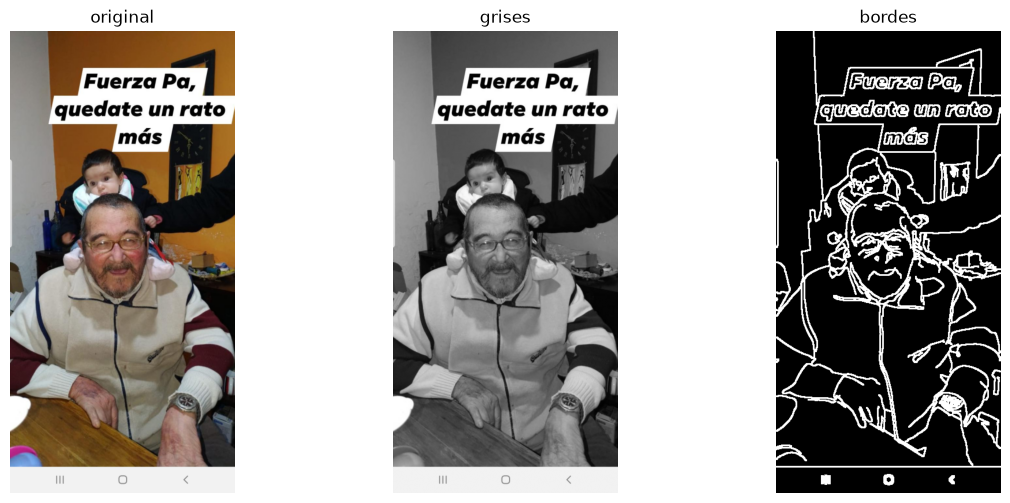

In [3]:
def reducir(img, alto=800):
    escala = alto / img.shape[0]
    chica = cv2.resize(img, None, fx=escala, fy=escala, interpolation=cv2.INTER_AREA)
    return chica, escala

chica, escala = reducir(img)
gris = cv2.cvtColor(chica, cv2.COLOR_RGB2GRAY)
suave = cv2.GaussianBlur(gris, (5, 5), 0)
bordes = cv2.Canny(suave, 50, 150)
bordes = cv2.dilate(bordes, np.ones((3, 3), np.uint8), iterations=1)

fig, ejes = plt.subplots(1, 3, figsize=(14, 6))
for eje, im, titulo in zip(ejes, [chica, gris, bordes], ["original", "grises", "bordes"]):
    eje.imshow(im, cmap=None if im.ndim == 3 else "gray")
    eje.set_title(titulo)
    eje.axis("off")
plt.show()

## 4. Encontrar las esquinas

Busca contornos, identifica uno con cuatro esquinas y dibuja su contorno.

esquinas: None


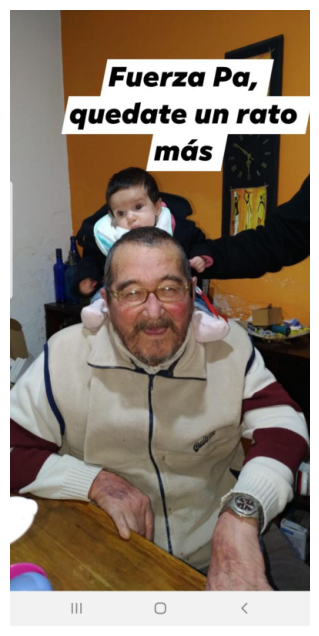

In [4]:
resultado_contornos = cv2.findContours(
    bordes,
    cv2.RETR_LIST,
    cv2.CHAIN_APPROX_SIMPLE,
)
contornos = resultado_contornos[-2] if len(resultado_contornos) == 3 else resultado_contornos[0]
contornos = sorted(contornos, key=cv2.contourArea, reverse=True)[:5]

esquinas = None
for c in contornos:
    perimetro = cv2.arcLength(c, True)
    aprox = cv2.approxPolyDP(c, 0.02 * perimetro, True)
    if len(aprox) == 4:
        esquinas = aprox.reshape(4, 2).astype("float32")
        break

print("esquinas:", esquinas)

vista = chica.copy()
if esquinas is not None:
    cv2.polylines(vista, [esquinas.astype(np.int32)], True, (255, 0, 0), 4)
plt.figure(figsize=(6, 8))
plt.imshow(vista)
plt.axis("off")
plt.show()

## 5. Enderezar el documento

Ordena las esquinas y aplica una transformacion de perspectiva.

In [5]:
def ordenar(pts):
    suma = pts.sum(axis=1)
    dif = np.diff(pts, axis=1).ravel()
    return np.array([pts[np.argmin(suma)],   # arriba-izquierda
                     pts[np.argmin(dif)],    # arriba-derecha
                     pts[np.argmax(suma)],   # abajo-derecha
                     pts[np.argmax(dif)]],   # abajo-izquierda
                    dtype="float32")

def enderezar(img, pts):
    tl, tr, br, bl = pts
    ancho = int(max(np.linalg.norm(br - bl), np.linalg.norm(tr - tl)))
    alto = int(max(np.linalg.norm(tr - br), np.linalg.norm(tl - bl)))
    destino = np.array([[0, 0], [ancho - 1, 0],
                        [ancho - 1, alto - 1], [0, alto - 1]], dtype="float32")
    M = cv2.getPerspectiveTransform(pts, destino)
    return cv2.warpPerspective(img, M, (ancho, alto))

if esquinas is not None:
    pts = ordenar(esquinas) / escala   # de vuelta a la escala de la foto original
    resultado = enderezar(img, pts)
    plt.figure(figsize=(6, 8))
    plt.imshow(resultado)
    plt.axis("off")
    plt.show()

## 6. Eliminar una leyenda

Selecciona un area rectangular y usa inpainting para reconstruir aproximadamente el fondo.

In [7]:
# Herramienta con goma, deshacer y rehacer.
%matplotlib widget
try:
    if isinstance(resultado, np.ndarray):
        BASE = resultado.copy()
    else:
        BASE = img.copy()
except NameError:
    BASE = img.copy()

alto_base, ancho_base = BASE.shape[:2]
limpia = BASE.copy()
confirmada = BASE.copy()
candidato = None
historial = []
rehacer = []
mascara_goma = np.zeros(BASE.shape[:2], dtype=np.uint8)

x1 = widgets.IntSlider(description="Izquierda", min=0, max=ancho_base - 1, value=0)
y1 = widgets.IntSlider(description="Superior", min=0, max=alto_base - 1, value=0)
x2 = widgets.IntSlider(description="Derecha", min=1, max=ancho_base, value=ancho_base)
y2 = widgets.IntSlider(description="Inferior", min=1, max=alto_base, value=alto_base)
radio = widgets.IntSlider(description="Relleno", min=1, max=40, value=12)
expandir_mascara = widgets.IntSlider(description="Expandir seleccion", min=0, max=30, value=8)
metodo = widgets.Dropdown(
    options=[("Telea", cv2.INPAINT_TELEA), ("Navier-Stokes", cv2.INPAINT_NS)],
    value=cv2.INPAINT_TELEA,
    description="Metodo:",
)
vista_prev = widgets.Output()
modo_goma = widgets.Checkbox(description="Goma con el mouse", value=True)
aplicar = widgets.Button(description="Aplicar goma", button_style="primary")
deshacer = widgets.Button(description="Deshacer")
rehacer_boton = widgets.Button(description="Rehacer")
reiniciar = widgets.Button(description="Volver al inicio")
guardar = widgets.Button(description="Guardar resultado")
confirmar = widgets.Button(description="Confirmar cambio", button_style="success")
cancelar = widgets.Button(description="Cancelar cambio", button_style="warning")
tamano_goma = widgets.IntSlider(description="Tamano goma", min=3, max=80, value=20)
pintando = False

def mostrar_prev(_=None):
    izquierda = min(x1.value, x2.value)
    derecha = max(x1.value, x2.value)
    superior = min(y1.value, y2.value)
    inferior = max(y1.value, y2.value)

    vista = limpia.copy()
    cv2.rectangle(vista, (izquierda, superior), (derecha, inferior), (255, 0, 0), 3)
    with vista_prev:
        vista_prev.clear_output(wait=True)
        fig, ax = plt.subplots(figsize=(8, 10))
        ax.imshow(vista)
        ax.axis("off")
        def dibujar_goma(event):
            global pintando, mascara_goma
            if not modo_goma.value or event.inaxes != ax or event.xdata is None:
                return
            if event.name == "button_press_event":
                pintando = True
            elif event.name == "button_release_event":
                pintando = False
            elif not pintando:
                return
            x = int(round(event.xdata))
            y = int(round(event.ydata))
            cv2.circle(mascara_goma, (x, y), tamano_goma.value, 255, thickness=-1)
            vista_goma = limpia.copy()
            vista_goma[mascara_goma > 0] = [255, 0, 0]
            ax.images[0].set_data(vista_goma)
            fig.canvas.draw_idle()
        fig.canvas.mpl_connect("button_press_event", dibujar_goma)
        fig.canvas.mpl_connect("motion_notify_event", dibujar_goma)
        fig.canvas.mpl_connect("button_release_event", dibujar_goma)
        plt.show()

def eliminar(_):
    global limpia, mascara_goma, candidato

    izquierda = min(x1.value, x2.value)
    derecha = max(x1.value, x2.value)
    superior = min(y1.value, y2.value)
    inferior = max(y1.value, y2.value)

    mascara = np.zeros(BASE.shape[:2], dtype=np.uint8)
    cv2.rectangle(mascara, (izquierda, superior), (derecha, inferior), 255, thickness=-1)
    mascara = cv2.bitwise_or(mascara, mascara_goma)
    if not mascara.any():
        print("Seleccione un area o pase la goma sobre la leyenda")
        return
    expansion = expandir_mascara.value
    if expansion > 0:
        nucleo = np.ones((expansion * 2 + 1, expansion * 2 + 1), np.uint8)
        mascara = cv2.dilate(mascara, nucleo)

    relleno = cv2.inpaint(limpia, mascara, radio.value, metodo.value)
    relleno = cv2.bilateralFilter(relleno, d=9, sigmaColor=25, sigmaSpace=9)
    mascara_suave = cv2.GaussianBlur(mascara, (0, 0), 3)
    alfa = (mascara_suave.astype(np.float32) / 255.0)[..., None]
    candidato = np.clip(limpia.astype(np.float32) * (1.0 - alfa) + relleno.astype(np.float32) * alfa, 0, 255).astype(np.uint8)
    limpia = candidato.copy()
    mascara_goma = np.zeros(BASE.shape[:2], dtype=np.uint8)
    mostrar_prev()

def deshacer_cambio(_):
    global limpia
    if not historial:
        print("No hay cambios para deshacer")
        return
    rehacer.append(limpia.copy())
    limpia = historial.pop()
    mostrar_prev()

def rehacer_cambio(_):
    global limpia
    if not rehacer:
        print("No hay cambios para rehacer")
        return
    historial.append(limpia.copy())
    limpia = rehacer.pop()
    mostrar_prev()

def confirmar_cambio(_):
    global confirmada, limpia, candidato
    if candidato is None:
        print("No hay una vista previa para confirmar")
        return
    historial.append(confirmada.copy())
    rehacer.clear()
    confirmada = candidato.copy()
    limpia = confirmada.copy()
    candidato = None
    print("Cambio confirmado")
    mostrar_prev()

def cancelar_cambio(_):
    global limpia, candidato, mascara_goma
    if candidato is None:
        print("No hay una vista previa para cancelar")
        return
    limpia = confirmada.copy()
    candidato = None
    mascara_goma = np.zeros(BASE.shape[:2], dtype=np.uint8)
    print("Vista previa cancelada")
    mostrar_prev()

def reiniciar_cambio(_):
    global limpia, confirmada, candidato, mascara_goma
    if not np.array_equal(confirmada, BASE):
        historial.append(confirmada.copy())
    rehacer.clear()
    confirmada = BASE.copy()
    limpia = BASE.copy()
    candidato = None
    mascara_goma = np.zeros(BASE.shape[:2], dtype=np.uint8)
    mostrar_prev()

def guardar_resultado(_):
    global candidato
    if candidato is not None:
        print("Confirma o cancela la vista previa antes de guardar")
        return
    ruta_salida = CARPETA / "imagen_sin_leyenda.jpg"
    Image.fromarray(confirmada).save(ruta_salida)
    print("Guardado en:", ruta_salida)

for control in (x1, y1, x2, y2, radio, metodo, expandir_mascara):
    control.observe(mostrar_prev, names="value")
aplicar.on_click(eliminar)
deshacer.on_click(deshacer_cambio)
rehacer_boton.on_click(rehacer_cambio)
confirmar.on_click(confirmar_cambio)
cancelar.on_click(cancelar_cambio)
reiniciar.on_click(reiniciar_cambio)
guardar.on_click(guardar_resultado)

print("Herramienta cargada")
display(widgets.HBox([x1, y1]))
display(widgets.HBox([x2, y2]))
display(widgets.HBox([radio, expandir_mascara, metodo, tamano_goma]))
display(modo_goma)
display(widgets.HBox([aplicar, confirmar, cancelar, deshacer, rehacer_boton, reiniciar, guardar]))
display(vista_prev)
mostrar_prev()

  

Herramienta cargada


Checkbox(value=True, description='Goma con el mouse')

Output()